# Entrenamiento

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# ── Cargar datos ──
X_train = pd.read_csv("csv/X_train.csv")
X_val   = pd.read_csv("csv/X_val.csv")
X_test  = pd.read_csv("csv/X_test.csv")
y_train = pd.read_csv("csv/y_train.csv").squeeze()
y_val   = pd.read_csv("csv/y_val.csv").squeeze()
y_test  = pd.read_csv("csv/y_test.csv").squeeze()

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (16795, 25) | Val: (3599, 25) | Test: (3599, 25)


In [2]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_v, y_v):

    modelo.fit(X_tr, y_tr)
    pred_tr = modelo.predict(X_tr)
    pred_v  = modelo.predict(X_v)

    metricas = {
        "modelo":    nombre,
        "MAE_train": round(mean_absolute_error(y_tr, pred_tr), 6),
        "MAE_val":   round(mean_absolute_error(y_v,  pred_v),  6),
        "RMSE_train":round(np.sqrt(mean_squared_error(y_tr, pred_tr)), 6),
        "RMSE_val":  round(np.sqrt(mean_squared_error(y_v,  pred_v)),  6),
        "R2_train":  round(r2_score(y_tr, pred_tr), 6),
        "R2_val":    round(r2_score(y_v,  pred_v),  6),
    }

    print(f"\n{'='*50}")
    print(f"  {nombre}")
    print(f"{'='*50}")
    print(f"  MAE   → train: {metricas['MAE_train']}  |  val: {metricas['MAE_val']}")
    print(f"  RMSE  → train: {metricas['RMSE_train']}  |  val: {metricas['RMSE_val']}")
    print(f"  R²    → train: {metricas['R2_train']}  |  val: {metricas['R2_val']}")

    return metricas, modelo

In [3]:
resultados = []

# Linear Regression
m, _ = evaluar_modelo("LinearRegression", LinearRegression(), X_train, y_train, X_val, y_val)
resultados.append(m)

# Ridge
m, _ = evaluar_modelo("Ridge", Ridge(alpha=1.0), X_train, y_train, X_val, y_val)
resultados.append(m)


  LinearRegression
  MAE   → train: 0.019054  |  val: 0.01885
  RMSE  → train: 0.02573  |  val: 0.025087
  R²    → train: 0.642347  |  val: 0.648459

  Ridge
  MAE   → train: 0.019053  |  val: 0.018848
  RMSE  → train: 0.02573  |  val: 0.025087
  R²    → train: 0.642347  |  val: 0.648459


In [4]:
# Random Forest
m, rf = evaluar_modelo(
    "RandomForest",
    RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1),
    X_train, y_train, X_val, y_val
)
resultados.append(m)

# Gradient Boosting
m, gb = evaluar_modelo(
    "GradientBoosting",
    GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42),
    X_train, y_train, X_val, y_val
)
resultados.append(m)

# XGBoost
m, xgb = evaluar_modelo(
    "XGBoost",
    XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
                 subsample=0.8, colsample_bytree=0.8,
                 random_state=42, verbosity=0),
    X_train, y_train, X_val, y_val
)
resultados.append(m)


  RandomForest
  MAE   → train: 0.004659  |  val: 0.005963
  RMSE  → train: 0.00852  |  val: 0.010957
  R²    → train: 0.960787  |  val: 0.932937

  GradientBoosting
  MAE   → train: 0.005168  |  val: 0.005937
  RMSE  → train: 0.008643  |  val: 0.010143
  R²    → train: 0.959644  |  val: 0.942537

  XGBoost
  MAE   → train: 0.003908  |  val: 0.005331
  RMSE  → train: 0.00636  |  val: 0.009126
  R²    → train: 0.978148  |  val: 0.953477


Dispositivo: cuda
  Epoch  10 | Loss train: 0.005240 | Loss val: 0.005288
  Epoch  20 | Loss train: 0.001195 | Loss val: 0.001246
  Epoch  30 | Loss train: 0.000563 | Loss val: 0.000340
  Epoch  40 | Loss train: 0.000373 | Loss val: 0.000220
  Epoch  50 | Loss train: 0.000226 | Loss val: 0.000125
  Epoch  60 | Loss train: 0.000165 | Loss val: 0.000104
  Epoch  70 | Loss train: 0.000158 | Loss val: 0.000133
  Epoch  80 | Loss train: 0.000137 | Loss val: 0.000087
  Epoch  90 | Loss train: 0.000111 | Loss val: 0.000074
  Epoch 100 | Loss train: 0.000114 | Loss val: 0.000069


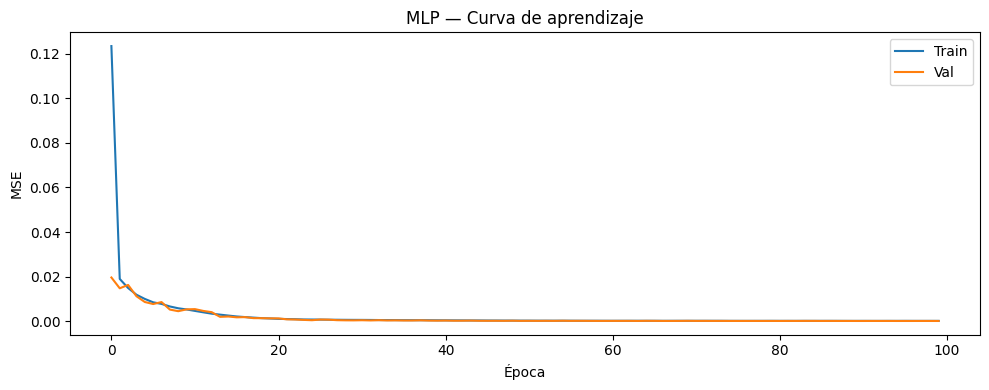


MLP → MAE val: 0.004906 | R² val: 0.961185


In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device_ml = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device_ml}")

# ── Preparar tensores ──
def to_tensor(X, y=None):
    Xt = torch.tensor(X.values, dtype=torch.float32)
    if y is not None:
        yt = torch.tensor(y.values, dtype=torch.float32).unsqueeze(1)
        return Xt, yt
    return Xt

Xtr, ytr = to_tensor(X_train, y_train)
Xv,  yv  = to_tensor(X_val,   y_val)

train_ds = TensorDataset(Xtr, ytr)
train_dl = DataLoader(train_ds, batch_size=256, shuffle=True)

# ── Arquitectura MLP ──
class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

mlp = MLP(X_train.shape[1]).to(device_ml)

optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
criterion = nn.MSELoss()

# ── Entrenamiento ──
EPOCHS     = 100
historial  = {"train": [], "val": []}
mejor_val  = float("inf")

for epoch in range(1, EPOCHS + 1):

    mlp.train()
    loss_tr = 0
    for Xb, yb in train_dl:
        Xb, yb = Xb.to(device_ml), yb.to(device_ml)
        optimizer.zero_grad()
        loss = criterion(mlp(Xb), yb)
        loss.backward()
        optimizer.step()
        loss_tr += loss.item() * len(Xb)

    loss_tr /= len(train_ds)

    mlp.eval()
    with torch.no_grad():
        pred_v = mlp(Xv.to(device_ml)).cpu().squeeze().numpy()

    loss_v = mean_squared_error(y_val, pred_v)
    scheduler.step(loss_v)

    historial["train"].append(loss_tr)
    historial["val"].append(loss_v)

    if loss_v < mejor_val:
        mejor_val = loss_v
        torch.save(mlp.state_dict(), "csv/mlp_best.pt")

    if epoch % 10 == 0:
        print(f"  Epoch {epoch:3d} | Loss train: {loss_tr:.6f} | Loss val: {loss_v:.6f}")

# ── Curva de aprendizaje ──
plt.figure(figsize=(10, 4))
plt.plot(historial["train"], label="Train")
plt.plot(historial["val"],   label="Val")
plt.title("MLP — Curva de aprendizaje")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

# ── Evaluar MLP ──
mlp.load_state_dict(torch.load("csv/mlp_best.pt"))
mlp.eval()
with torch.no_grad():
    pred_tr_mlp = mlp(Xtr.to(device_ml)).cpu().squeeze().numpy()
    pred_v_mlp  = mlp(Xv.to(device_ml)).cpu().squeeze().numpy()

m_mlp = {
    "modelo":    "MLP",
    "MAE_train": round(mean_absolute_error(y_train, pred_tr_mlp), 6),
    "MAE_val":   round(mean_absolute_error(y_val,   pred_v_mlp),  6),
    "RMSE_train":round(np.sqrt(mean_squared_error(y_train, pred_tr_mlp)), 6),
    "RMSE_val":  round(np.sqrt(mean_squared_error(y_val,   pred_v_mlp)),  6),
    "R2_train":  round(r2_score(y_train, pred_tr_mlp), 6),
    "R2_val":    round(r2_score(y_val,   pred_v_mlp),  6),
}
resultados.append(m_mlp)
print(f"\nMLP → MAE val: {m_mlp['MAE_val']} | R² val: {m_mlp['R2_val']}")


COMPARACIÓN DE MODELOS
          modelo  MAE_train  MAE_val  RMSE_val  R2_train   R2_val
             MLP   0.004847 0.004906  0.008336  0.963443 0.961185
         XGBoost   0.003908 0.005331  0.009126  0.978148 0.953477
GradientBoosting   0.005168 0.005937  0.010143  0.959644 0.942537
    RandomForest   0.004659 0.005963  0.010957  0.960787 0.932937
           Ridge   0.019053 0.018848  0.025087  0.642347 0.648459
LinearRegression   0.019054 0.018850  0.025087  0.642347 0.648459


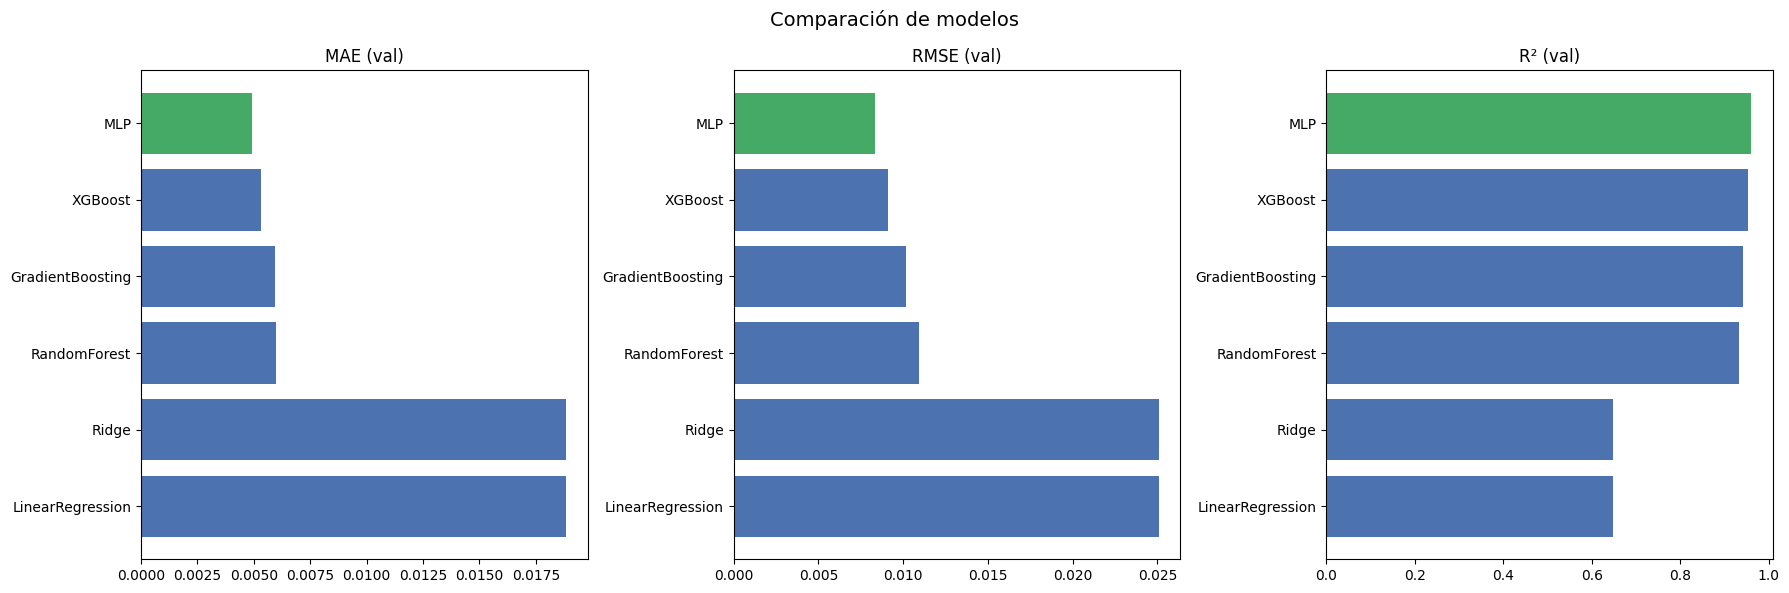


✅ Resultados guardados en csv/resultados_modelos.csv


In [8]:
df_resultados = pd.DataFrame(resultados).sort_values("MAE_val")

print("\n" + "="*70)
print("COMPARACIÓN DE MODELOS")
print("="*70)
print(df_resultados[["modelo", "MAE_train", "MAE_val",
                      "RMSE_val", "R2_train", "R2_val"]].to_string(index=False))

# Gráfica comparativa
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Comparación de modelos", fontsize=14)

for ax, metrica, titulo in zip(
    axes,
    ["MAE_val", "RMSE_val", "R2_val"],
    ["MAE (val)", "RMSE (val)", "R² (val)"]
):
    colores = ["#44AA66" if i == 0 else "#4C72B0"
               for i in range(len(df_resultados))]
    ax.barh(df_resultados["modelo"], df_resultados[metrica], color=colores)
    ax.set_title(titulo)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Guardar resultados
df_resultados.to_csv("csv/resultados_modelos.csv", index=False)
print("\n✅ Resultados guardados en csv/resultados_modelos.csv")

In [7]:
# Reentrenar XGBoost con train+val para maximizar datos
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

xgb_final = XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbosity=0
)
xgb_final.fit(X_train_full, y_train_full)

pred_test = xgb_final.predict(X_test)

print("=" * 50)
print("EVALUACIÓN FINAL EN TEST — XGBoost")
print("=" * 50)
print(f"MAE:  {mean_absolute_error(y_test, pred_test):.6f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred_test)):.6f}")
print(f"R²:   {r2_score(y_test, pred_test):.6f}")

# Guardar modelo final
import joblib
joblib.dump(xgb_final, "csv/xgb_final.pkl")
print("\n✅ Modelo guardado: csv/xgb_final.pkl")

EVALUACIÓN FINAL EN TEST — XGBoost
MAE:  0.005270
RMSE: 0.009098
R²:   0.957151

✅ Modelo guardado: csv/xgb_final.pkl
